# Examine experiment results

The BigQuery SQL returns analysis-ready subscription-level data. `summarize_price_points` groups that data by any requested dimensions and calculates user counts, contact rate, churn rate, save rate, gamer rate, revenue, and CNRC.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from google.cloud import bigquery
from IPython.display import display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.examine_result_helpers import plot_metric, summarize_price_points
from src.refresh_price_point_raw_data import replace_csv

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Load detail data

In [2]:
project_id = "gannett-datascience"
sql_path = PROJECT_ROOT / "src" / "sql" / "price_point_detail_data.sql"
client = bigquery.Client(project=project_id)
df = client.query(sql_path.read_text()).to_dataframe(create_bqstorage_client=False)

print(
    f"Loaded {len(df):,} mature subscriptions across "
    f"{df['market'].nunique(dropna=True):,} markets."
)

Loaded 97,538 mature subscriptions across 210 markets.


## 2. Summaries

Pass any columns to `dimensions`. Subset `df` with normal pandas code when an analysis needs a specific population.

In [3]:
print("Overall summary:")
overall = summarize_price_points(df)
display(overall.round(2))

print("Summary by cohort and treatment:")
cohort_treatment = summarize_price_points(df, ["cohort", "treatment"])
display(cohort_treatment.round(2))

print("Summary by start price group and treatment of Three-Offer Cohort:")
three_offer = df.loc[df["cohort"].eq("Three-Offer Cohort")]
price_treatment = summarize_price_points(
    three_offer, ["start_price_group", "treatment"]
)
display(price_treatment.round(2))

print("Summary by gamer type and treatment of contacted users:")
contacted = df.loc[df["contacted"].eq(1)]
gamer_treatment = summarize_price_points(
    contacted, ["gamer_type", "treatment"]
)
display(
    gamer_treatment[[
        "gamer_type", "treatment", "total_users",
        "churn_rate", "total_revenue", "cnrc",
    ]].round(2)
)

Overall summary:


,overall,total_users,contacted_users,saved_users,stopped_users,gamer_users,total_revenue,contact_rate,churn_rate,save_rate,gamer_rate,cnrc
0,Overall,97538,18967,7085,11882,4709,"226,467.010",0.190,0.630,0.370,0.250,11.940


Summary by cohort and treatment:


,cohort,treatment,total_users,contacted_users,saved_users,stopped_users,gamer_users,total_revenue,contact_rate,churn_rate,save_rate,gamer_rate,cnrc
0,Three-Offer Cohort,Control,18495,3808,2148,1660,1095,"60,655.690",0.210,0.440,0.560,0.290,15.930
1,Three-Offer Cohort,Midpoint,18402,3760,1267,2493,1011,"46,959.140",0.200,0.660,0.340,0.270,12.490
2,Three-Offer Cohort,Tiered,18318,3669,956,2713,987,"35,653.520",0.200,0.740,0.260,0.270,9.720
3,Two-Offer Cohort,Control,21249,3998,1751,2247,862,"48,453.090",0.190,0.560,0.440,0.220,12.120
4,Two-Offer Cohort,Midpoint,21074,3732,963,2769,754,"34,745.570",0.180,0.740,0.260,0.200,9.310


Summary by start price group and treatment of Three-Offer Cohort:


,start_price_group,treatment,total_users,contacted_users,saved_users,stopped_users,gamer_users,total_revenue,contact_rate,churn_rate,save_rate,gamer_rate,cnrc
0,1. <=4.99,Control,1689,796,631,165,257,"9,997.340",0.470,0.210,0.790,0.320,12.560
1,1. <=4.99,Midpoint,1659,783,374,409,241,"8,362.990",0.470,0.520,0.480,0.310,10.680
2,1. <=4.99,Tiered,1634,766,251,515,228,"6,368.260",0.470,0.670,0.330,0.300,8.310
3,2. <=9.99,Control,4218,1524,1022,502,503,"33,144.100",0.360,0.330,0.670,0.330,21.750
4,2. <=9.99,Midpoint,4202,1521,535,986,451,"23,407.240",0.360,0.650,0.350,0.300,15.390
5,2. <=9.99,Tiered,4126,1426,427,999,435,"19,383.280",0.350,0.700,0.300,0.310,13.590
6,3. <=14.99,Control,5714,781,317,464,208,"9,767.560",0.140,0.590,0.410,0.270,12.510
7,3. <=14.99,Midpoint,5733,776,222,554,204,"8,504.950",0.140,0.710,0.290,0.260,10.960
8,3. <=14.99,Tiered,5733,761,163,598,191,"5,659.810",0.130,0.790,0.210,0.250,7.440
9,4. <=16.99,Control,15,2,1,1,1,0.000,0.130,0.500,0.500,0.500,0.000


Summary by gamer type and treatment of contacted users:


,gamer_type,treatment,total_users,churn_rate,total_revenue,cnrc
0,Not Gamer,Control,5849,0.620,"74,763.170",12.780
1,Not Gamer,Midpoint,5727,0.810,"43,244.640",7.550
2,Not Gamer,Tiered,2682,0.860,"14,400.100",5.370
3,Repeat Restart,Control,148,1.000,0.000,0.000
4,Repeat Restart,Midpoint,441,1.000,14.990,0.030
5,Repeat Restart,Tiered,320,1.000,15.990,0.050
6,Seek and paid lower rate,Control,51,0.000,"2,354.950",46.180
7,Seek and paid lower rate,Midpoint,272,0.010,"14,063.670",51.700
8,Seek and paid lower rate,Tiered,149,0.010,"9,604.570",64.460
9,"Seek lower rate, still paid offered rate",Control,1758,0.090,"31,990.660",18.200


In [4]:
print("Summary by market with at least 200 total users (descending ordered by contact rate):")
market_summary = (
    summarize_price_points(df, ["market"])
    .loc[lambda result: result["total_users"].ge(200)]
    .sort_values("contact_rate", ascending=False)
)
display(market_summary.head(30).round(2))

market_summary_path = PROJECT_ROOT / "src/notebooks/tables/examine_result/market_summary.csv"
replace_csv(market_summary_path, market_summary)
print(f"Saved market summary to {market_summary_path}")

Summary by market with at least 200 total users (descending ordered by contact rate):


,market,total_users,contacted_users,saved_users,stopped_users,gamer_users,total_revenue,contact_rate,churn_rate,save_rate,gamer_rate,cnrc
59,Fort Myers,231,104,41,63,34,"1,390.680",0.450,0.610,0.390,0.330,13.370
170,Sioux Falls,285,109,42,67,27,"1,667.600",0.380,0.610,0.390,0.250,15.300
175,SpringfieldMO,376,142,50,92,24,"1,808.910",0.380,0.650,0.350,0.170,12.740
9,Appleton,338,124,67,57,45,"2,753.560",0.370,0.460,0.540,0.360,22.210
46,Detroit,2832,995,463,532,295,"15,380.210",0.350,0.530,0.470,0.300,15.460
84,Indianapolis,1215,414,165,249,115,"6,066.220",0.340,0.600,0.400,0.280,14.650
45,Des Moines,895,296,129,167,79,"4,797.630",0.330,0.560,0.440,0.270,16.210
58,Fort Collins,591,190,87,103,45,"3,072.110",0.320,0.540,0.460,0.240,16.170
125,Nashville,625,194,68,126,46,"2,383.200",0.310,0.650,0.350,0.240,12.280
70,Green Bay,450,139,70,69,44,"2,848.640",0.310,0.500,0.500,0.320,20.490


Saved market summary to /Users/ying/Documents/DEV/work/stop_save_pChurn/src/notebooks/tables/examine_result/market_summary.csv


## 3. Charts

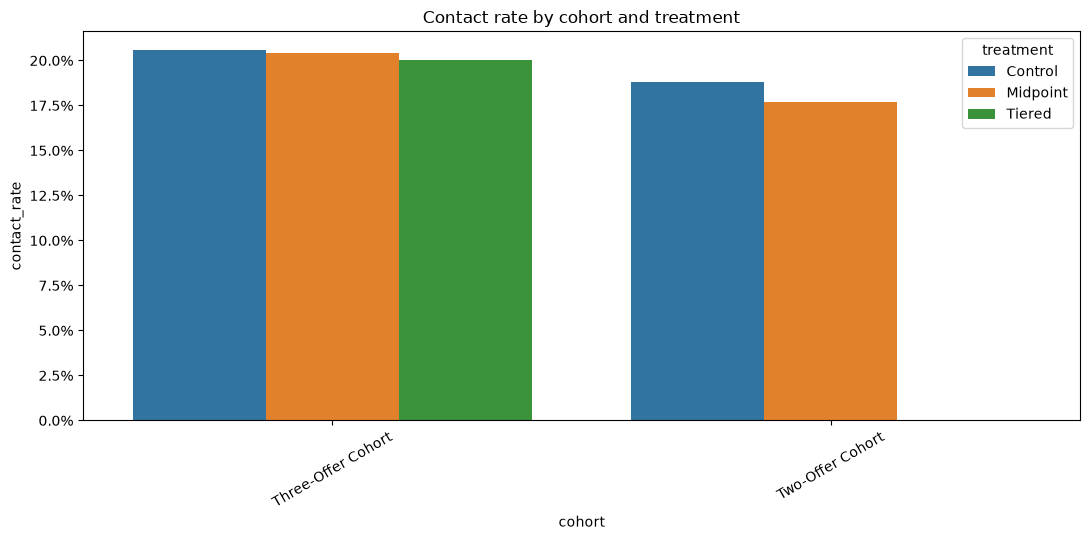

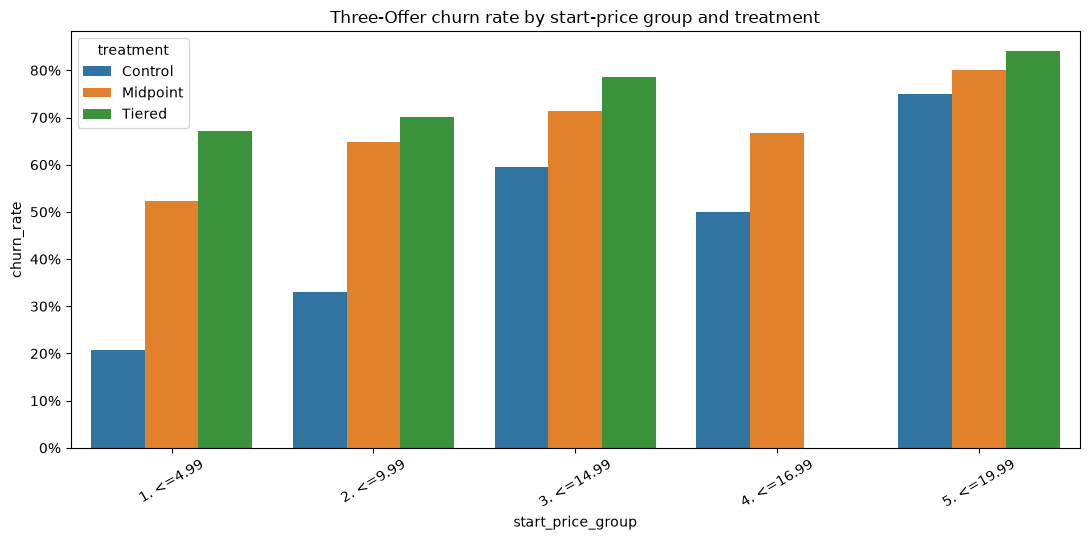

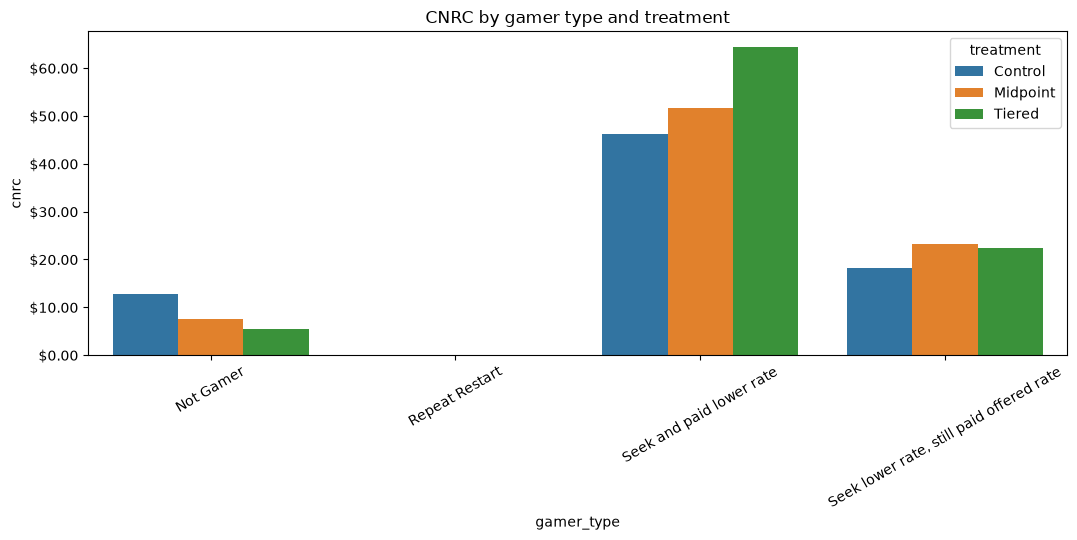

In [5]:
plot_metric(
    cohort_treatment,
    metric="contact_rate",
    x="cohort",
    hue="treatment",
    title="Contact rate by cohort and treatment",
)
plt.show()

plot_metric(
    price_treatment,
    metric="churn_rate",
    x="start_price_group",
    hue="treatment",
    title="Three-Offer churn rate by start-price group and treatment",
)
plt.show()

plot_metric(
    gamer_treatment,
    metric="cnrc",
    x="gamer_type",
    hue="treatment",
    title="CNRC by gamer type and treatment",
)
plt.show()